# De la donnée à la décision — Statistiques pour les Experts Data

## TP 03 — Statistiques inférentielles

**Auteur :** Bassem Ben Hamed — `bassem.benhamed@enetcom.usf.tn`

**Contenu :** Modules 6 à 10 de la formation (Partie 3 — Statistiques inférentielles).

**Dataset fil rouge :** *Pharmaceutical Sales Data* (Kaggle / Milan Zdravković).

Ce notebook accompagne le module 03 Statistiques Inférentielles. Format :
1. **Rappel théorique** (formule + intuition).
2. **Code commenté** en français.
3. **Interprétation business** systématique.

> Les formules sont rappelées dans le notebook même si elles figurent dans les slides — la répétition est volontaire pour fixer les notations.

## Sommaire

- **Setup** — imports, chargement du dataset
- **Module 6** — De l'échantillon à la population
  - Distribution d'échantillonnage, démonstration du TCL
  - Intervalle de confiance (moyenne, proportion)
  - Taille d'échantillon nécessaire
- **Module 7** — Tests d'hypothèses
  - p-value, erreurs Type I/II, puissance
  - Taille d'effet (Cohen's $d$)
  - Comparaisons multiples (Bonferroni, BH)
- **Module 8** — Choisir le bon test
  - $t$-test (1, 2 indépendants, Welch, apparié)
  - Mann-Whitney, Wilcoxon
  - ANOVA, Kruskal-Wallis
  - $\chi^2$, test $z$ de proportion
  - Tests de normalité
- **Module 9** — Régression linéaire
  - OLS, $R^2$, lecture du summary
  - Régression multiple, variables catégorielles
  - Hypothèses (résidus, QQ-plot), VIF
- **Module 10** — Régression logistique
  - Modèle, lecture en odds ratios
  - Matrice de confusion, précision/rappel/$F_1$
  - ROC, AUC, seuil de décision
- **Synthèse**

## Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                              roc_curve, roc_auc_score, precision_recall_curve)
from pathlib import Path

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

### Chargement du dataset

In [2]:
csv_path = Path('dataset') / 'salesdaily.csv'
df_raw = pd.read_csv(csv_path, parse_dates=['datum'], dayfirst=False)
df_raw = df_raw.rename(columns={'datum': 'date'}).set_index('date').sort_index()

categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df = df_raw[categories].copy()

JOURS_FR = {0: 'lundi', 1: 'mardi', 2: 'mercredi', 3: 'jeudi',
            4: 'vendredi', 5: 'samedi', 6: 'dimanche'}

def saison(mois):
    return ('hiver' if mois in (12, 1, 2)
            else 'printemps' if mois in (3, 4, 5)
            else 'été' if mois in (6, 7, 8)
            else 'automne')

# DataFrame enrichi pour les régressions
df_feat = df.copy()
df_feat['jour_semaine'] = df_feat.index.dayofweek.map(JOURS_FR)
df_feat['mois']         = df_feat.index.month
df_feat['saison']       = df_feat.index.month.map(saison)
df_feat['weekend']      = (df_feat.index.dayofweek >= 5).astype(int)
df_feat['annee']        = df_feat.index.year

print(f'Forme : {df.shape}')
df_feat.head()

Forme : (2106, 8)


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,jour_semaine,mois,saison,weekend,annee
date,,,,,,,,,,,,,
2014-01-02,0.000,3.670,3.400,32.400,7.000,0.000,0.000,2.000,jeudi,1,hiver,0,2014
2014-01-03,8.000,4.000,4.400,50.600,16.000,0.000,20.000,4.000,vendredi,1,hiver,0,2014
2014-01-04,2.000,1.000,6.500,61.850,10.000,0.000,9.000,1.000,samedi,1,hiver,1,2014
2014-01-05,4.000,3.000,7.000,41.100,8.000,0.000,3.000,0.000,dimanche,1,hiver,1,2014
2014-01-06,5.000,1.000,4.500,21.700,16.000,2.000,6.000,2.000,lundi,1,hiver,0,2014


---
## Module 6 — De l'échantillon à la population

Objectif : passer de « ce qu'on a observé » à « ce qu'on peut conclure sur la population ».

### 6.1 Distribution d'échantillonnage

Si on répétait l'expérience un grand nombre de fois (chaque fois un nouvel échantillon de taille $n$), on obtiendrait une distribution de **moyennes échantillonnales** $\bar{x}_1, \bar{x}_2, \dots$

Trois propriétés à vérifier numériquement :
- $\mathbb{E}[\bar{X}] = \mu$ (estimateur sans biais)
- $\mathrm{Var}(\bar{X}) = \sigma^2/n$
- Forme tend vers $\mathcal{N}$ quand $n$ grandit (TCL)

In [3]:
# On considère df['N02BE'] comme la 'population'. On en tire des échantillons.
population = df['N02BE'].values
mu_pop  = population.mean()
sig_pop = population.std(ddof=0)

# 5000 échantillons de taille n
n_ech = 5000
moyennes_30 = [np.random.choice(population, size=30, replace=True).mean()
               for _ in range(n_ech)]

print(f'Population : μ = {mu_pop:.2f}, σ = {sig_pop:.2f}')
print(f'Moyennes échantillonnales (n=30) : moyenne = {np.mean(moyennes_30):.2f},'
      f' écart-type = {np.std(moyennes_30):.2f}')
print(f'Théorique σ/√n = {sig_pop / np.sqrt(30):.2f}')

Population : μ = 29.92, σ = 15.59
Moyennes échantillonnales (n=30) : moyenne = 29.88, écart-type = 2.87
Théorique σ/√n = 2.85


**Lecture :** la moyenne des moyennes échantillonnales colle à $\mu$ (estimateur sans biais), et leur écart-type approche $\sigma/\sqrt{n}$ — c'est l'**erreur standard**.

### 6.2 Théorème central limite — démonstration visuelle

$$\bar{X}_n \;\approx\; \mathcal{N}\!\left(\mu, \frac{\sigma^2}{n}\right) \quad \text{pour } n \text{ grand}$$

**Peu importe la loi d'origine.** Vérifions sur une distribution très asymétrique : la log-normale.

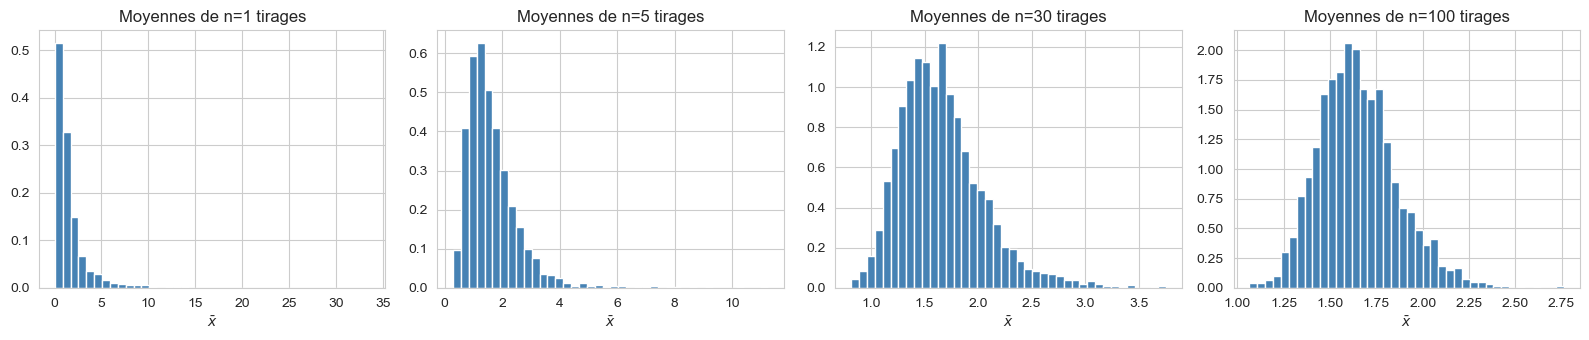

In [4]:
# On part d'une log-normale (très asymétrique)
rng = np.random.default_rng(42)
loi = stats.lognorm(s=1.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, n in zip(axes, [1, 5, 30, 100]):
    moyennes = [rng.choice(loi.rvs(10000), size=n).mean() for _ in range(3000)]
    ax.hist(moyennes, bins=40, density=True, color='steelblue', edgecolor='white')
    ax.set_title(f'Moyennes de n={n} tirages')
    ax.set_xlabel(r'$\bar{x}$')
plt.tight_layout(); plt.show()

**Interprétation :** à $n = 1$ on retrouve la log-normale brute (très asymétrique). Dès $n = 30$, la distribution est presque gaussienne. À $n = 100$, indistinguable d'une normale. C'est ce qui justifie d'utiliser la normale (et le $z$-score) pour construire la majorité des tests et IC.

### 6.3 Intervalle de confiance sur une moyenne

**Formule** (cas $\sigma$ inconnu, $n$ pas trop petit) :
$$\mathrm{IC}_{1-\alpha} = \left[\bar{x} - t_{n-1,\,1-\alpha/2}\cdot \frac{s}{\sqrt{n}},\;\bar{x} + t_{n-1,\,1-\alpha/2}\cdot \frac{s}{\sqrt{n}}\right]$$

Pour $n$ grand, $t_{n-1} \to z$ (normale standard) avec $z_{0{,}975} = 1{,}96$.

In [5]:
# IC à 95 % sur la moyenne mensuelle des ventes N02BE
ventes_mensuelles = df['N02BE'].resample('ME').sum()
n = len(ventes_mensuelles)
x_bar = ventes_mensuelles.mean()
s     = ventes_mensuelles.std(ddof=1)
se    = s / np.sqrt(n)

alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, df=n-1)
ic = (x_bar - t_crit * se, x_bar + t_crit * se)

print(f'n = {n} mois')
print(f'x̄ = {x_bar:.2f}')
print(f's  = {s:.2f}')
print(f'SE = s/√n = {se:.2f}')
print(f't_(n-1, 0.975) = {t_crit:.3f}')
print(f'IC à 95 % : [{ic[0]:.2f}, {ic[1]:.2f}]')

n = 70 mois
x̄ = 900.08
s  = 305.43
SE = s/√n = 36.51
t_(n-1, 0.975) = 1.995
IC à 95 % : [827.25, 972.90]


**Lecture business :** « Avec une confiance de 95 %, la vraie moyenne mensuelle des ventes N02BE se situe dans cet intervalle. »

**Lecture fréquentiste correcte :** « Si on répétait cette expérience, 95 % des intervalles construits contiendraient la vraie moyenne. »

### 6.4 Intervalle de confiance sur une proportion

$$\mathrm{IC}_{1-\alpha} = \hat{p} \;\pm\; z_{1-\alpha/2}\cdot \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

In [6]:
# Proportion de 'jours de forte vente' (N02BE > P90)
seuil = df['N02BE'].quantile(0.90)
succes = (df['N02BE'] > seuil).sum()
n_total = len(df)
p_hat = succes / n_total

se = np.sqrt(p_hat * (1 - p_hat) / n_total)
z = stats.norm.ppf(0.975)
ic = (p_hat - z*se, p_hat + z*se)

print(f'p̂ = {p_hat:.4f}    SE = {se:.4f}')
print(f'IC à 95 % : [{ic[0]:.4f}, {ic[1]:.4f}]')
print(f'Soit en pourcentage : [{100*ic[0]:.2f} %, {100*ic[1]:.2f} %]')

p̂ = 0.0997    SE = 0.0065
IC à 95 % : [0.0869, 0.1125]
Soit en pourcentage : [8.69 %, 11.25 %]


### 6.5 Taille d'échantillon nécessaire

Pour estimer une proportion à $\pm E$ près, avec confiance $1 - \alpha$ :
$$n \geq \frac{z_{1-\alpha/2}^2 \cdot p(1-p)}{E^2}$$

Cas le plus défavorable : $p = 0{,}5$ (variance maximale).

In [7]:
# Combien d'observations pour estimer un taux de conversion à ±2 points près ?
z = stats.norm.ppf(0.975)
E = 0.02
p_max = 0.5
n_required = (z**2 * p_max * (1 - p_max)) / E**2
print(f'Taille d\'échantillon nécessaire (95 %, ±2 pts, p~0.5) : {int(np.ceil(n_required))}')

# Combien pour ±1 point ? (la marge est divisée par 2 → n multiplié par 4)
n_2 = (z**2 * p_max * (1 - p_max)) / 0.01**2
print(f'Pour ±1 point : {int(np.ceil(n_2))} (≈ 4× plus)')

Taille d'échantillon nécessaire (95 %, ±2 pts, p~0.5) : 2401
Pour ±1 point : 9604 (≈ 4× plus)


**Conséquence pratique :** la taille d'échantillon croît en $1/E^2$. Diviser la marge d'erreur par 2 demande de **multiplier** par 4 le nombre d'observations.

---
## Module 7 — Tests d'hypothèses : la logique

### 7.1 Logique du test

**Procédure :**
1. On formule $H_0$ (pas d'effet) et $H_1$ (effet).
2. On suppose $H_0$ vraie, on observe les données.
3. Si elles sont *très improbables* sous $H_0$ → on rejette $H_0$.

**p-value :**
$$p = \mathbb{P}(\text{données au moins aussi extrêmes} \mid H_0 \text{ vraie})$$

C'est une **probabilité conditionnelle** (rappel Module 4).

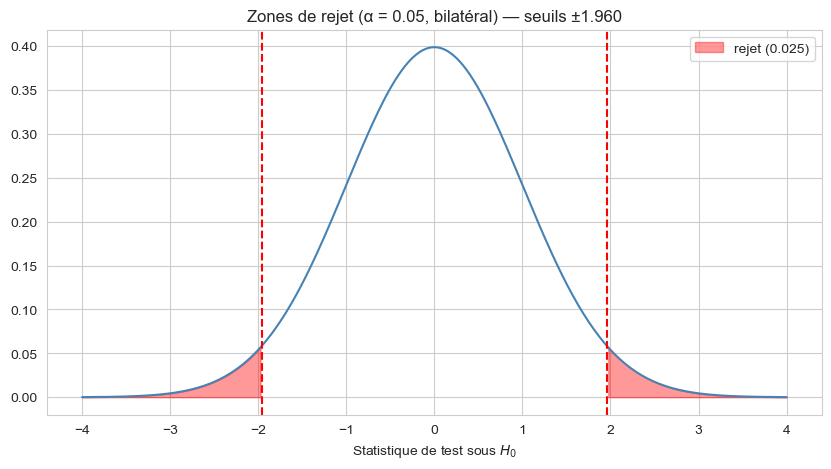

In [8]:
# Visualisation de la zone de rejet pour un test bilatéral à α = 0.05
x = np.linspace(-4, 4, 400)
pdf = stats.norm.pdf(x)
z_crit = stats.norm.ppf(0.975)

fig, ax = plt.subplots()
ax.plot(x, pdf, color='steelblue')
ax.fill_between(x, 0, pdf, where=(x >= z_crit), color='red', alpha=0.4, label=f'rejet ({0.025})')
ax.fill_between(x, 0, pdf, where=(x <= -z_crit), color='red', alpha=0.4)
ax.axvline(z_crit, color='red', ls='--')
ax.axvline(-z_crit, color='red', ls='--')
ax.set_title(f'Zones de rejet (α = 0.05, bilatéral) — seuils ±{z_crit:.3f}')
ax.set_xlabel('Statistique de test sous $H_0$')
ax.legend(); plt.show()

### 7.2 Erreurs Type I et Type II

| | $H_0$ vraie | $H_0$ fausse |
|---|---|---|
| Rejette $H_0$ | **Type I** ($\alpha$) | OK |
| Ne rejette pas | OK | **Type II** ($\beta$) |

**Démonstration par simulation :** on génère 5000 expériences sous $H_0$ (pas d'effet) et on compte combien sont « significatives » au seuil 5 %.

In [9]:
rng = np.random.default_rng(0)
alpha = 0.05
n_sim = 5000
rejets = 0
for _ in range(n_sim):
    # Sous H0 : 2 groupes de 50 tirés de la même normale
    a = rng.normal(0, 1, 50)
    b = rng.normal(0, 1, 50)
    _, p = stats.ttest_ind(a, b)
    if p < alpha:
        rejets += 1

print(f'Faux positifs (Type I) : {rejets}/{n_sim} = {rejets/n_sim:.3f}')
print(f'Attendu (= α)          : {alpha}')

Faux positifs (Type I) : 247/5000 = 0.049
Attendu (= α)          : 0.05


**Lecture :** sous $H_0$, on rejette ~5 % des fois — c'est exactement ce que $\alpha = 0{,}05$ garantit. Cette ligne est calibrée par construction.

### 7.3 Puissance statistique

$$\text{Puissance} = 1 - \beta = \mathbb{P}(\text{rejeter } H_0 \mid H_1 \text{ vraie})$$

Calculons la puissance d'un $t$-test selon la taille d'échantillon, pour un effet de taille $d = 0{,}3$ (moyen-faible).

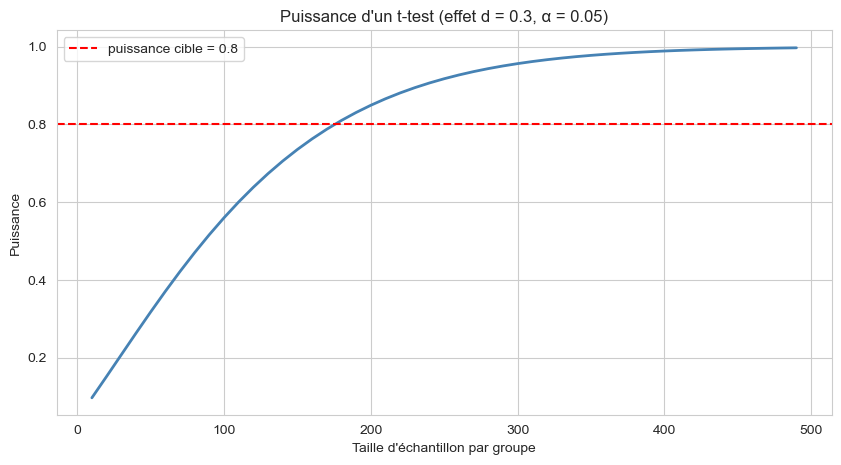

Pour atteindre 80 % de puissance : n ≥ 176 par groupe


In [10]:
from statsmodels.stats.power import TTestIndPower

power_calculator = TTestIndPower()
tailles = np.arange(10, 500, 10)
puissances = [power_calculator.power(effect_size=0.3, nobs1=n, alpha=0.05) for n in tailles]

fig, ax = plt.subplots()
ax.plot(tailles, puissances, color='steelblue', lw=2)
ax.axhline(0.8, color='red', ls='--', label='puissance cible = 0.8')
ax.set_xlabel('Taille d\'échantillon par groupe')
ax.set_ylabel('Puissance')
ax.set_title(f'Puissance d\'un t-test (effet d = 0.3, α = 0.05)')
ax.legend(); plt.show()

n_min = power_calculator.solve_power(effect_size=0.3, alpha=0.05, power=0.8)
print(f'Pour atteindre 80 % de puissance : n ≥ {int(np.ceil(n_min))} par groupe')

### 7.4 Taille d'effet — Cohen's $d$

$$d = \frac{\bar{x}_1 - \bar{x}_2}{s_{\text{pooled}}}$$

**Repères :** $|d| < 0{,}2$ négligeable, $\approx 0{,}5$ moyen, $\geq 0{,}8$ fort.

In [11]:
def cohens_d(x1, x2):
    n1, n2 = len(x1), len(x2)
    s_pooled = np.sqrt(((n1-1)*x1.var(ddof=1) + (n2-1)*x2.var(ddof=1)) / (n1 + n2 - 2))
    return (x1.mean() - x2.mean()) / s_pooled

# Comparons week-end vs semaine sur N02BE
x_we  = df.loc[df.index.dayofweek >= 5, 'N02BE']
x_sem = df.loc[df.index.dayofweek <  5, 'N02BE']

d = cohens_d(x_sem, x_we)
_, p = stats.ttest_ind(x_sem, x_we, equal_var=False)
print(f"Moyenne semaine = {x_sem.mean():.2f},  Moyenne week-end = {x_we.mean():.2f}")
print(f"Cohen's d  = {d:.3f}   (effet : {'négligeable' if abs(d)<0.2 else 'faible' if abs(d)<0.5 else 'moyen' if abs(d)<0.8 else 'fort'})")
print(f'p-value    = {p:.3g}')

Moyenne semaine = 28.49,  Moyenne week-end = 33.49
Cohen's d  = -0.324   (effet : faible)
p-value    = 3.83e-09


**À retenir :** une p-value très petite ne dit *rien* de l'amplitude de l'effet. Sur des gros datasets pharma, on a souvent $p \to 0$ pour des effets pourtant minimes. Toujours reporter $d$ ou la différence absolue/relative.

### 7.5 Comparaisons multiples — Bonferroni / Benjamini-Hochberg

Si on teste $k$ hypothèses au seuil $\alpha$, on attend $\sim \alpha k$ tests « significatifs » par pur hasard.

Démonstration : 50 tests sous $H_0$ (donc tous nuls).

In [12]:
rng = np.random.default_rng(7)
k = 50
p_values = []
for _ in range(k):
    a = rng.normal(0, 1, 100)
    b = rng.normal(0, 1, 100)
    p_values.append(stats.ttest_ind(a, b).pvalue)

p_values = np.array(p_values)
alpha = 0.05

from statsmodels.stats.multitest import multipletests

rej_brut, _, _, _ = multipletests(p_values, alpha=alpha, method='bonferroni')
rej_bh, p_bh, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')

print(f'{k} tests sous H0 (rien ne se passe)')
print(f'Significatifs sans correction        : {(p_values < alpha).sum()}')
print(f'Significatifs après Bonferroni       : {rej_brut.sum()}')
print(f'Significatifs après Benjamini-Hochberg : {rej_bh.sum()}')

50 tests sous H0 (rien ne se passe)
Significatifs sans correction        : 2
Significatifs après Bonferroni       : 0
Significatifs après Benjamini-Hochberg : 0


**Interprétation :** sans correction, on trouve plusieurs « significatifs » alors que rien ne se passe. Bonferroni est strict, BH plus tolérant. À choisir selon le contexte (médecine → Bonferroni ; data exploration → BH).

---
## Module 8 — Choisir le bon test

### 8.1 $t$-test à 1 échantillon

$$t = \frac{\bar{x} - \mu_0}{s/\sqrt{n}} \sim t_{n-1}$$

**Question :** la moyenne mensuelle de N02BE diffère-t-elle de la valeur contractuelle de référence (par ex. 800) ?

In [13]:
ventes_mensuelles = df['N02BE'].resample('ME').sum()
mu_0 = 800

stat, p = stats.ttest_1samp(ventes_mensuelles, popmean=mu_0)
print(f'Moyenne observée : {ventes_mensuelles.mean():.2f}')
print(f'Référence μ₀     : {mu_0}')
print(f't = {stat:.3f}, p = {p:.4f}')

Moyenne observée : 900.08
Référence μ₀     : 800
t = 2.741, p = 0.0078


**Lecture :** si $p < 0{,}05$, on rejette $H_0$ : la moyenne mensuelle diffère significativement de 800. Sinon, on n'a pas assez de preuves pour conclure.

### 8.2 $t$-test à 2 échantillons (Welch)

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

**Question :** les ventes du week-end diffèrent-elles de celles de la semaine ?

In [14]:
x_we  = df.loc[df.index.dayofweek >= 5, 'N02BE']
x_sem = df.loc[df.index.dayofweek <  5, 'N02BE']

# Welch (equal_var=False) — recommandé par défaut
t, p = stats.ttest_ind(x_sem, x_we, equal_var=False)
print(f'Moyenne semaine  : {x_sem.mean():.2f}')
print(f'Moyenne week-end : {x_we.mean():.2f}')
print(f't = {t:.3f}, p = {p:.3g}')

Moyenne semaine  : 28.49
Moyenne week-end : 33.49
t = -5.951, p = 3.83e-09


### 8.3 Mann-Whitney $U$ — alternative non paramétrique

Quand la distribution n'est pas normale ou les outliers sont présents, Mann-Whitney travaille sur les **rangs** plutôt que les valeurs.

In [15]:
u, p_mw = stats.mannwhitneyu(x_sem, x_we, alternative='two-sided')
print(f'Mann-Whitney U = {u:.0f}, p = {p_mw:.3g}')

# Comparaison : t-test vs Mann-Whitney
print()
print(f't-test Welch       : p = {p:.3g}')
print(f'Mann-Whitney (rangs) : p = {p_mw:.3g}')

Mann-Whitney U = 389729, p = 5.89e-07

t-test Welch       : p = 3.83e-09
Mann-Whitney (rangs) : p = 5.89e-07


**Robustesse :** sur ce dataset, les deux tests concordent. Quand ils divergent, c'est typiquement à cause d'outliers ou de skewness — privilégier Mann-Whitney.

### 8.4 ANOVA — comparer plusieurs groupes

$$F = \frac{MS_{\text{inter}}}{MS_{\text{intra}}} \sim F(g-1, n-g)$$

**Question :** les ventes diffèrent-elles entre les jours de la semaine ?

In [16]:
df_long = df['N02BE'].copy()
groupes = [df.loc[df.index.dayofweek == j, 'N02BE'].values for j in range(7)]

f_stat, p_anova = stats.f_oneway(*groupes)
print(f'F = {f_stat:.2f}, p = {p_anova:.3g}')

# Variante non paramétrique : Kruskal-Wallis
h_stat, p_kw = stats.kruskal(*groupes)
print(f'Kruskal-Wallis : H = {h_stat:.2f}, p = {p_kw:.3g}')

F = 7.69, p = 3.46e-08
Kruskal-Wallis : H = 27.43, p = 0.00012


**Lecture :** une F-statistique élevée et $p \to 0$ confirment que les ventes diffèrent fortement selon le jour. ANOVA dit *qu'il y a* une différence, mais pas *où* — pour la localiser, il faut des tests post-hoc (Tukey HSD).

### 8.5 Test du $\chi^2$ d'indépendance

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

**Question :** la catégorie leader des ventes dépend-elle de la saison ? (exemple repris de TP 01)

In [17]:
leader = df.idxmax(axis=1).rename('leader')
saison_par_date = pd.Series(df.index.month, index=df.index).map(saison).rename('saison')
tab = pd.crosstab(leader, saison_par_date)

chi2, p, dof, _ = stats.chi2_contingency(tab)
print(f'χ² = {chi2:.2f},  ddl = {dof},  p = {p:.3g}')
tab

χ² = 86.27,  ddl = 15,  p = 4.9e-12


saison,automne,hiver,printemps,été
leader,,,,
M01AB,2,17,10,1
N02BA,0,0,1,0
N02BE,478,481,510,493
N05B,8,8,13,44
R03,5,3,16,12
R06,0,0,2,2


### 8.6 Test $z$ de proportions — A/B test

$$z = \frac{\hat{p}_1 - \hat{p}_2}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}$$

In [18]:
from statsmodels.stats.proportion import proportions_ztest

# Cas pratique : A/B test fictif
succes = np.array([230, 280])    # nombres de conversions
n      = np.array([5000, 5000])  # tailles des groupes

z, p = proportions_ztest(succes, n)
print(f'Variant A : {succes[0]/n[0]*100:.2f} %')
print(f'Variant B : {succes[1]/n[1]*100:.2f} %')
print(f'z = {z:.3f}, p = {p:.4f}')

Variant A : 4.60 %
Variant B : 5.60 %
z = -2.273, p = 0.0230


**Lecture :** la différence d'1 point ($\Delta = 5{,}6\,\% - 4{,}6\,\%$) est-elle statistiquement significative ? La p-value répond. Mais il faut encore se demander si la différence est **business-significative** (coût d'implémentation vs gain).

### 8.7 Tests de normalité

Avant un test paramétrique, on vérifie la normalité.

Shapiro-Wilk           : p = 5.5e-29
Kolmogorov-Smirnov     : p = 4.56e-14

Si p < 0.05 → on rejette la normalité.


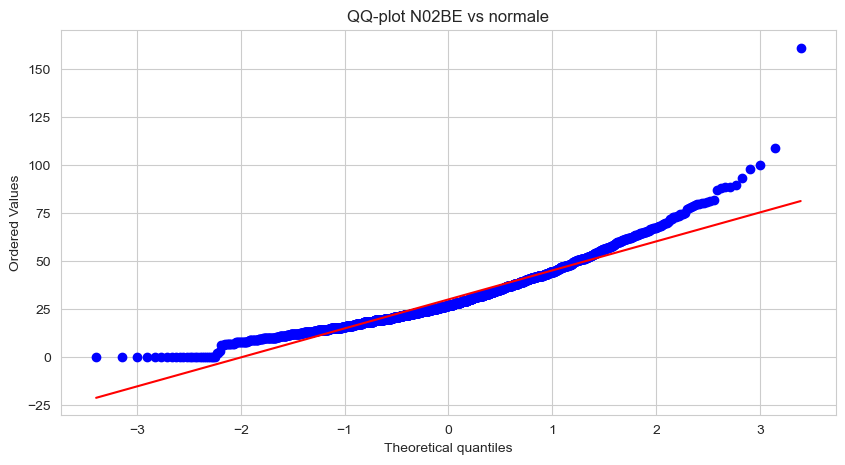

In [19]:
x = df['N02BE'].sample(2000, random_state=42)  # Shapiro-Wilk a une limite à n=5000

stat_sw, p_sw = stats.shapiro(x)
stat_ks, p_ks = stats.kstest(x, 'norm', args=(x.mean(), x.std()))

print(f'Shapiro-Wilk           : p = {p_sw:.3g}')
print(f'Kolmogorov-Smirnov     : p = {p_ks:.3g}')
print()
print('Si p < 0.05 → on rejette la normalité.')

# QQ-plot — souvent plus informatif que les tests sur grands échantillons
fig, ax = plt.subplots()
stats.probplot(x, dist='norm', plot=ax)
ax.set_title('QQ-plot N02BE vs normale')
plt.show()

**Attention :** sur un grand échantillon, les tests de normalité rejettent **presque toujours** $H_0$. Préférer le QQ-plot et le bon sens.

---
## Module 9 — Régression linéaire

### 9.1 Régression simple

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \quad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$

Solution OLS : $\hat{\beta}_1 = \mathrm{Cov}(X,Y)/\mathrm{Var}(X) = r \cdot s_Y/s_X$

Modélisons les ventes M01AB en fonction des ventes N02BE.

β₀ = 4.090
β₁ = 0.032
R² = 0.032


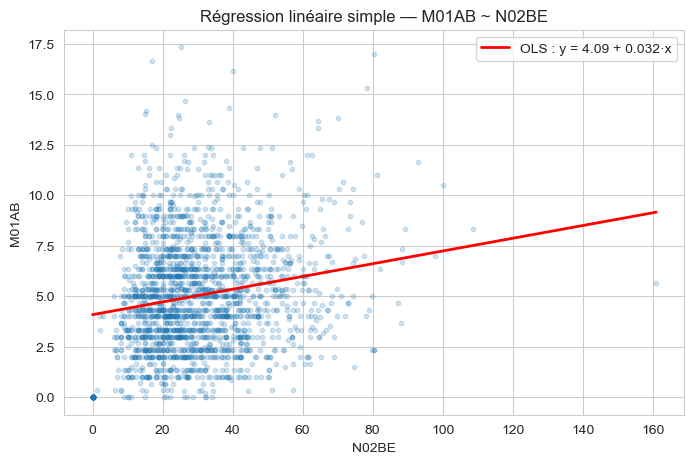

In [20]:
X = df['N02BE']
y = df['M01AB']

X_const = sm.add_constant(X)
modele = sm.OLS(y, X_const).fit()

print(f'β₀ = {modele.params["const"]:.3f}')
print(f'β₁ = {modele.params["N02BE"]:.3f}')
print(f'R² = {modele.rsquared:.3f}')

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X, y, alpha=0.2, s=10)
x_range = np.linspace(X.min(), X.max(), 100)
ax.plot(x_range, modele.params['const'] + modele.params['N02BE'] * x_range,
        color='red', lw=2, label=f'OLS : y = {modele.params["const"]:.2f} + {modele.params["N02BE"]:.3f}·x')
ax.set_xlabel('N02BE'); ax.set_ylabel('M01AB')
ax.set_title('Régression linéaire simple — M01AB ~ N02BE')
ax.legend(); plt.show()

**Interprétation :** $\beta_1 \approx 0{,}1$ signifie qu'une augmentation de 10 unités N02BE est associée à une augmentation d'environ 1 unité M01AB. Le $R^2$ donne la fraction de variance de M01AB expliquée par N02BE.

### 9.2 Régression multiple — toutes choses égales par ailleurs

$$y = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p + \varepsilon$$

**Lecture cruciale :** $\beta_j$ est l'effet de $x_j$ **toutes les autres variables tenues constantes**.

In [21]:
# Modèle : ventes N02BE expliquées par jour de la semaine + saison + année
modele_mult = smf.ols('N02BE ~ C(jour_semaine) + C(saison) + annee', data=df_feat).fit()
print(modele_mult.summary().tables[1])

                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                    -426.6272    358.021     -1.192      0.234   -1128.741     275.487
C(jour_semaine)[T.jeudi]       -5.2348      1.103     -4.745      0.000      -7.398      -3.071
C(jour_semaine)[T.lundi]       -4.2036      1.103     -3.810      0.000      -6.367      -2.040
C(jour_semaine)[T.mardi]       -5.0832      1.103     -4.608      0.000      -7.247      -2.920
C(jour_semaine)[T.mercredi]    -5.2992      1.104     -4.799      0.000      -7.465      -3.134
C(jour_semaine)[T.samedi]       0.1759      1.103      0.159      0.873      -1.988       2.340
C(jour_semaine)[T.vendredi]    -4.8118      1.103     -4.361      0.000      -6.975      -2.648
C(saison)[T.hiver]              3.5195      0.856      4.114      0.000       1.842       5.197
C(saison)[T.printemps]         -9.2983  

**Lecture du tableau :**
- `coef` : estimation $\hat{\beta}_j$.
- `std err` : erreur standard.
- `P>|t|` : p-value bilatérale ($H_0 : \beta_j = 0$).
- `[0.025, 0.975]` : IC à 95 % sur le coefficient.

**Lecture business :** chaque coefficient est l'effet « net » de la variable, après avoir contrôlé les autres. Le coefficient `C(jour_semaine)[T.dimanche]` mesure l'écart moyen aux ventes du dimanche par rapport à la modalité de référence (lundi par défaut, ordre alphabétique).

### 9.3 Hypothèses du modèle — diagnostic des résidus

Quatre hypothèses :
- **Linéarité** : $\mathbb{E}[y \mid X] = X\beta$
- **Indépendance** des résidus
- **Homoscédasticité** : variance constante
- **Normalité** des résidus

Diagnostic visuel : graphique des résidus + QQ-plot.

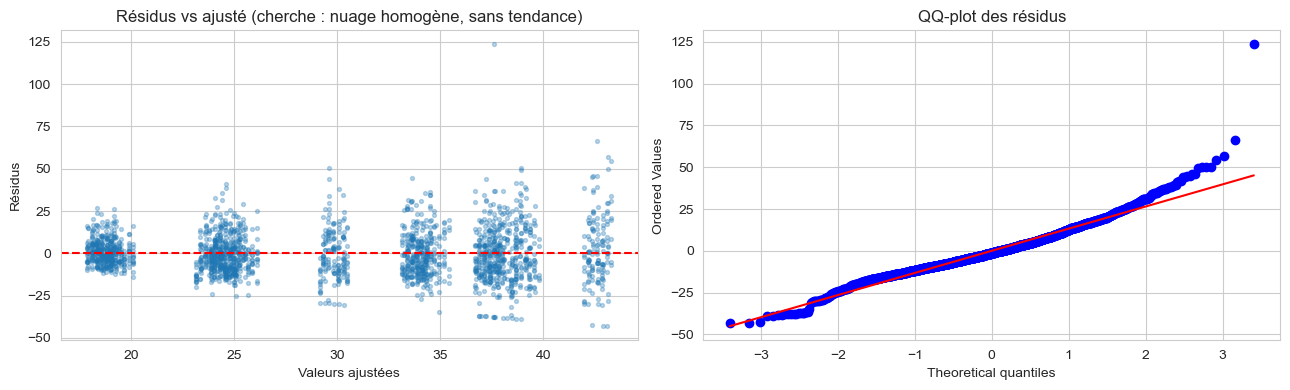

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Résidus vs valeurs ajustées
axes[0].scatter(modele_mult.fittedvalues, modele_mult.resid, alpha=0.3, s=8)
axes[0].axhline(0, color='red', ls='--')
axes[0].set_xlabel('Valeurs ajustées')
axes[0].set_ylabel('Résidus')
axes[0].set_title('Résidus vs ajusté (cherche : nuage homogène, sans tendance)')

# QQ-plot des résidus
stats.probplot(modele_mult.resid, dist='norm', plot=axes[1])
axes[1].set_title('QQ-plot des résidus')
plt.tight_layout(); plt.show()

**Interprétation :**
- Si le nuage de gauche montre une **forme** (entonnoir, courbe) → hypothèse de linéarité ou homoscédasticité violée.
- Si le QQ-plot dévie de la diagonale → résidus non gaussiens (les p-values sont alors approximatives, pas fausses).
- Sur un dataset pharma avec saisonnalité, les résidus sont rarement parfaits — les conclusions restent utiles si on garde ces limites en tête.

### 9.4 Multicolinéarité — VIF

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2}$$

où $R_j^2$ est obtenu en régressant $x_j$ sur toutes les autres variables explicatives.

**Repères :** VIF < 5 OK, VIF ≥ 10 multicolinéarité sévère.

In [23]:
# VIF sur des variables numériques (on ajoute des features dérivées potentiellement corrélées)
X_vif = pd.DataFrame({
    'N02BE': df['N02BE'],
    'M01AB': df['M01AB'],
    'M01AE': df['M01AE'],
    'N02BA': df['N02BA'],
})
X_vif = sm.add_constant(X_vif)

vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif

,variable,VIF
0,const,9.182
1,N02BE,1.142
2,M01AB,1.066
3,M01AE,1.128
4,N02BA,1.072


**Lecture :** plus le VIF est élevé, plus la variable est redondante avec les autres. Si VIF $\geq 10$ pour une variable, on la retire (ou on combine avec d'autres en composante principale).

---
## Module 10 — Régression logistique

### 10.1 Modèle logistique

$$\mathrm{logit}\!\left(\mathbb{P}(Y = 1 \mid X)\right) = \ln\!\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots$$

Ou de manière équivalente :
$$p = \frac{1}{1 + \exp(-(\beta_0 + \beta_1 x_1 + \dots))}$$

**Cible binaire** : on définit `forte_vente_N02BE` = 1 si ventes > P75, 0 sinon.

In [24]:
df_feat['forte_N02BE'] = (df_feat['N02BE'] > df_feat['N02BE'].quantile(0.75)).astype(int)
print(df_feat['forte_N02BE'].value_counts(normalize=True).round(3))

forte_N02BE
0   0.750
1   0.250
Name: proportion, dtype: float64


### 10.2 Ajustement avec statsmodels — lecture en odds ratios

$$\mathrm{OR} = \exp(\beta_j)$$

In [25]:
modele_log = smf.logit(
    'forte_N02BE ~ C(jour_semaine) + C(saison) + annee',
    data=df_feat
).fit(disp=False)

# Tableau des odds ratios
or_table = pd.DataFrame({
    'coef': modele_log.params,
    'OR (=exp(coef))': np.exp(modele_log.params),
    'p-value': modele_log.pvalues,
}).round(3)
or_table

,coef,OR (=exp(coef)),p-value
Intercept,-116.188,0.000,0.089
C(jour_semaine)[T.jeudi],-1.019,0.361,0.000
C(jour_semaine)[T.lundi],-0.723,0.485,0.000
C(jour_semaine)[T.mardi],-0.661,0.516,0.001
C(jour_semaine)[T.mercredi],-0.938,0.391,0.000
C(jour_semaine)[T.samedi],-0.248,0.781,0.204
C(jour_semaine)[T.vendredi],-0.784,0.457,0.000
C(saison)[T.hiver],0.476,1.609,0.000
C(saison)[T.printemps],-0.984,0.374,0.000
C(saison)[T.été],-3.199,0.041,0.000


**Lecture business :**
- Pour chaque variable, $\mathrm{OR} > 1$ augmente les odds de forte vente, $\mathrm{OR} < 1$ les réduit.
- Exemple typique : `C(jour_semaine)[T.dimanche]` aura un OR très inférieur à 1 (les fortes ventes sont rares le dimanche).
- Toujours **présenter en probabilité au business**, jamais en odds. « Le dimanche réduit fortement la chance d'une grosse journée. »

### 10.3 Évaluation — matrice de confusion

| | Prédit 1 | Prédit 0 |
|---|---|---|
| **Réel 1** | TP | FN |
| **Réel 0** | FP | TN |

$$\text{Précision} = \frac{TP}{TP + FP}, \quad \text{Rappel} = \frac{TP}{TP + FN}, \quad F_1 = \frac{2 \cdot P \cdot R}{P + R}$$

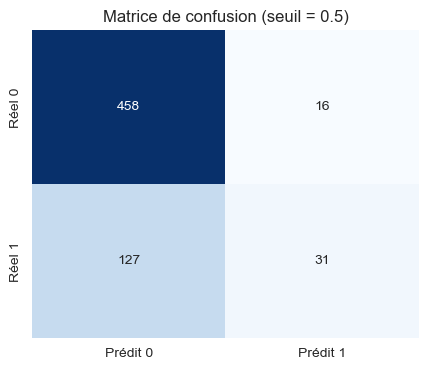

               precision    recall  f1-score   support

vente normale       0.78      0.97      0.86       474
  forte vente       0.66      0.20      0.30       158

     accuracy                           0.77       632
    macro avg       0.72      0.58      0.58       632
 weighted avg       0.75      0.77      0.72       632



In [26]:
# Préparation pour sklearn (one-hot manuel)
X = pd.get_dummies(df_feat[['jour_semaine', 'saison', 'annee']],
                   columns=['jour_semaine', 'saison'], drop_first=True).astype(float)
y = df_feat['forte_N02BE'].values

from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, y_tr)

# Prédictions au seuil par défaut (0.5)
y_pred = clf.predict(X_te)
y_proba = clf.predict_proba(X_te)[:, 1]

cm = confusion_matrix(y_te, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Prédit 0', 'Prédit 1'], yticklabels=['Réel 0', 'Réel 1'])
ax.set_title(f'Matrice de confusion (seuil = 0.5)')
plt.show()

print(classification_report(y_te, y_pred, target_names=['vente normale', 'forte vente']))

### 10.4 Courbe ROC et AUC

On trace TPR (= rappel) en fonction de FPR pour tous les seuils possibles.
AUC : aire sous la courbe. AUC = 1 parfait, AUC = 0,5 aléatoire.

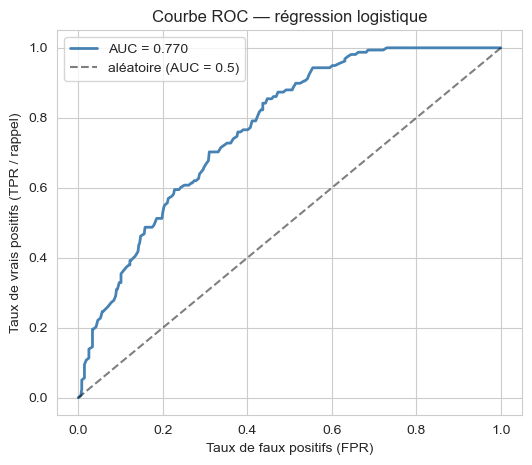

In [27]:
fpr, tpr, seuils = roc_curve(y_te, y_proba)
auc = roc_auc_score(y_te, y_proba)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='steelblue', lw=2, label=f'AUC = {auc:.3f}')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='aléatoire (AUC = 0.5)')
ax.set_xlabel('Taux de faux positifs (FPR)')
ax.set_ylabel('Taux de vrais positifs (TPR / rappel)')
ax.set_title(f'Courbe ROC — régression logistique')
ax.legend(); plt.show()

**Interprétation :** AUC > 0,8 indique un bon pouvoir discriminant. Mais attention sur classes déséquilibrées (cf. ci-dessous).

### 10.5 Choix du seuil de décision

Le seuil par défaut (0,5) n'est **pas** toujours optimal. Le bon seuil dépend du coût relatif des FP vs FN.

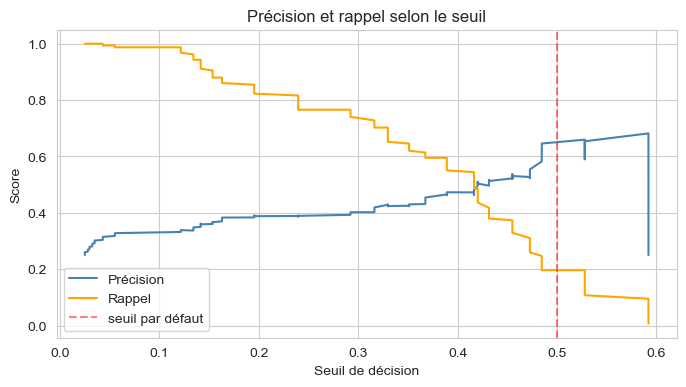

In [28]:
# Trade-off précision-rappel selon le seuil
p_arr, r_arr, s_arr = precision_recall_curve(y_te, y_proba)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(s_arr, p_arr[:-1], label='Précision', color='steelblue')
ax.plot(s_arr, r_arr[:-1], label='Rappel', color='orange')
ax.axvline(0.5, color='red', ls='--', alpha=0.5, label='seuil par défaut')
ax.set_xlabel('Seuil de décision')
ax.set_ylabel('Score')
ax.set_title('Précision et rappel selon le seuil')
ax.legend(); plt.show()

**Comment choisir :**
- Si **rater un positif coûte cher** (cancer, fraude) → baisser le seuil pour augmenter le rappel.
- Si **alarme à tort coûte cher** (filtre anti-spam, alerte oncall) → monter le seuil pour augmenter la précision.
- Documenter explicitement le seuil retenu et la justification métier.

---
## Synthèse de la Partie 3

À l'issue de ce TP, vous savez :
- Construire et interpréter un **intervalle de confiance** sur une moyenne ou une proportion.
- Calculer la **taille d'échantillon** pour une précision visée.
- Formuler $H_0$/$H_1$, lire correctement une **p-value**, distinguer significativité statistique et métier.
- Choisir le **test** adapté ($t$-test, Mann-Whitney, ANOVA, $\chi^2$, $z$ de proportions).
- Ajuster une **régression linéaire** multiple, lire un summary, vérifier les hypothèses, calculer les VIF.
- Ajuster une **régression logistique**, lire les odds ratios, évaluer (matrice de confusion, ROC, AUC), choisir un seuil.

### Cheatsheet — formules essentielles

| Concept | Formule |
|---|---|
| Erreur standard | $SE = s/\sqrt{n}$ |
| IC sur une moyenne | $\bar{x} \pm t_{n-1, 1-\alpha/2} \cdot s/\sqrt{n}$ |
| IC sur une proportion | $\hat{p} \pm z_{1-\alpha/2} \cdot \sqrt{\hat{p}(1-\hat{p})/n}$ |
| p-value | $\mathbb{P}(\text{stat} \geq \text{obs} \mid H_0)$ |
| Cohen's $d$ | $(\bar{x}_1 - \bar{x}_2) / s_{\text{pooled}}$ |
| $t$-test 1 ech. | $t = (\bar{x} - \mu_0)/(s/\sqrt{n})$ |
| Welch | $t = (\bar{x}_1 - \bar{x}_2)/\sqrt{s_1^2/n_1 + s_2^2/n_2}$ |
| ANOVA | $F = MS_{\text{inter}}/MS_{\text{intra}}$ |
| OLS | $\hat{\beta} = (X^\top X)^{-1} X^\top y$ |
| $R^2$ | $1 - SS_{\text{res}}/SS_{\text{tot}}$ |
| VIF | $1/(1 - R_j^2)$ |
| Logit | $\ln(p/(1-p)) = \beta_0 + \sum \beta_j x_j$ |
| Odds ratio | $\mathrm{OR} = \exp(\beta)$ |

### Suite

Le prochain TP (`04_series_temporelles.ipynb`) couvre la **Partie 4 — Séries temporelles** :
décomposition, stationnarité, ACF/PACF, SARIMA, Prophet, validation temporelle, détection d'anomalies.